# Estatísticas das Saídas do Treino-Malaria

In [2]:
import pandas as pd

predicoes = pd.read_csv('predicoes.csv', header=None)
probas = pd.read_csv('probabilidades.csv', header=None)

dengue_df  = pd.read_csv('../../database/Dengue.csv')
malaria_df = pd.read_csv('../../database/Malaria.csv')
shared_df  = pd.read_csv('../../database/Shared.csv')

df_malaria_teste = malaria_df[malaria_df['tipo'] == 'teste']

y_test  = df_malaria_teste['Result']
y_val   = dengue_df['Result']
y_shared= shared_df['Result']

 Model | Acura | Preci | Recal | F1-sco |   MCC  |   AUC
knn-te | 67.16 | 68.17 | 67.46 | 0.6692 | 0.3563 | 0.7187
knn-va | 73.48 | 74.76 | 75.07 | 0.7347 | 0.4983 | 0.8144
knn-sh | 76.03 | 77.19 | 76.03 | 0.7577 | 0.5321 | 0.8013
rfo-te | 72.43 | 73.10 | 72.66 | 0.7235 | 0.4576 | 0.7843
rfo-va | 80.43 | 80.83 | 81.59 | 0.8036 | 0.6241 | 0.8833
rfo-sh | 78.93 | 80.96 | 78.93 | 0.7857 | 0.5985 | 0.8354
svm-te | 68.33 | 69.57 | 68.66 | 0.6805 | 0.3822 | 0.7441
svm-va | 72.61 | 73.17 | 73.70 | 0.7254 | 0.4686 | 0.8047
svm-sh | 73.55 | 75.84 | 73.55 | 0.7296 | 0.4934 | 0.8004
xgb-te | 70.82 | 71.52 | 71.06 | 0.7072 | 0.4258 | 0.7830
xgb-va | 79.24 | 79.76 | 80.46 | 0.7918 | 0.6022 | 0.8713
xgb-sh | 77.69 | 79.77 | 77.69 | 0.7729 | 0.5742 | 0.8241


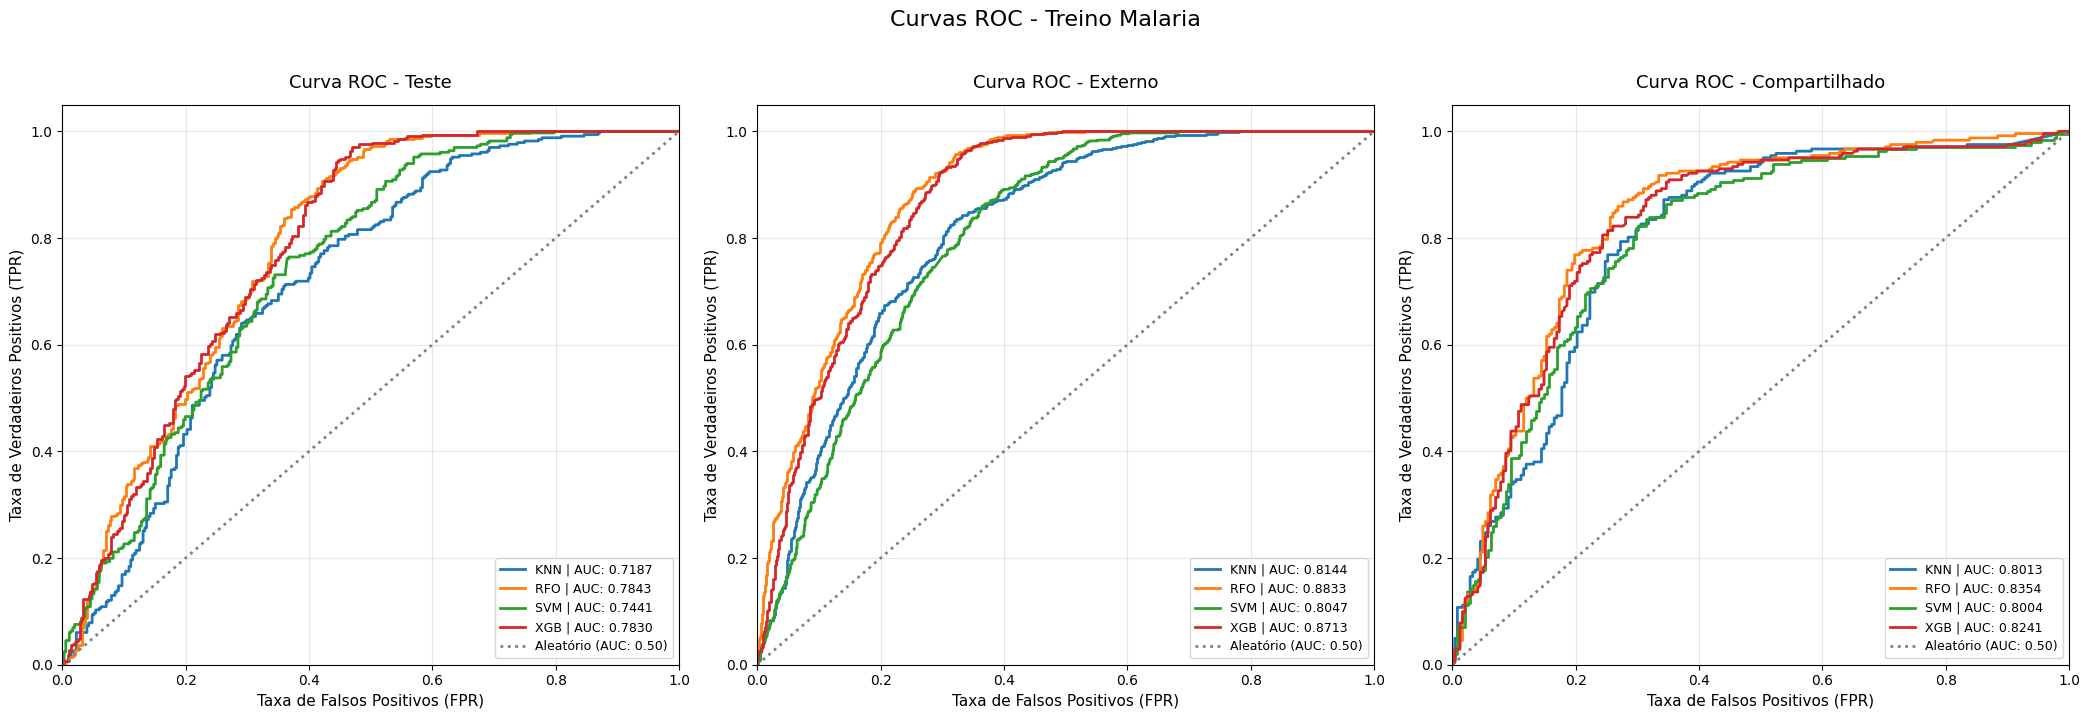

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             matthews_corrcoef, confusion_matrix, roc_curve)

print(' Model | Acura | Preci | Recal | F1-sco |   MCC  |   AUC')

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

eixos = {
    'teste':  axes[0],
    'valid':  axes[1],
    'shared': axes[2],
}

titulos = {
    'teste':  'Curva ROC - Teste',
    'valid':  'Curva ROC - Externo',
    'shared': 'Curva ROC - Compartilhado',
}

for i in range(len(predicoes)):
    y_pred  = predicoes.iloc[i, 2:].dropna().astype(int)
    y_proba = probas.iloc[i, 2:].dropna().astype(float)
    
    nome_modelo = predicoes.iloc[i, 0]

    if predicoes.iloc[i, 1] == 'teste':
        y = y_test.astype(int)
        tipo = 'te'
        chave = 'teste'
        nome_legenda = 'Teste'
    elif predicoes.iloc[i, 1] == 'shared':
        y = y_shared.astype(int)
        tipo = 'sh'
        chave = 'shared'
        nome_legenda = 'Compart.'
    else:
        y = y_val.astype(int)
        tipo = 'va'
        chave = 'valid'
        nome_legenda = 'Valid'

    # Métricas originais
    acuracia = accuracy_score(y, y_pred) * 100
    precisao = precision_score(y, y_pred, average='macro', zero_division=0) * 100
    recall   = recall_score(y, y_pred, average='macro', zero_division=0) * 100
    f1       = f1_score(y, y_pred, average='macro', zero_division=0)
    mcc      = matthews_corrcoef(y, y_pred)
    auc      = roc_auc_score(y, y_proba)

    print(f'{nome_modelo}-{tipo} | {acuracia:.2f} | {precisao:.2f} | {recall:.2f} | {f1:.4f} | {mcc:.4f} | {auc:.4f}')

    # Calcula a curva ROC e plota no subplot correspondente
    fpr, tpr, limiares = roc_curve(y, y_proba)
    ax = eixos[chave]
    ax.plot(fpr, tpr, lw=2, label=f'{nome_modelo.upper()} | AUC: {auc:.4f}')

# Configura cada subplot individualmente
for chave, ax in eixos.items():
    ax.plot([0, 1], [0, 1], color='gray', lw=2, linestyle=':', label='Aleatório (AUC: 0.50)')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('Taxa de Falsos Positivos (FPR)', fontsize=11)
    ax.set_ylabel('Taxa de Verdadeiros Positivos (TPR)', fontsize=11)
    ax.set_title(titulos[chave], fontsize=13, pad=12)
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Curvas ROC - Treino Malaria', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()